# Sales Loss Prediction | 04. Model

This notebook trains the XGBoost model, evaluates it honestly and uses it to rank the open orders. It has five parts:

1. Temporal split
2. The original approach vs the snapshot approach (the leakage of notebook 03, in numbers)
3. A second leakage: the order stage
4. Evaluation of the final model, including a comparison with the real probability
5. Explanation with SHAP and scoring of the open orders

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
import xgboost as xgb

warnings.filterwarnings("ignore", message="IProgress not found")  # progress bar warning from shap, not relevant here
import shap
from pathlib import Path
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

plt.style.use("ggplot")
plt.rcParams.update({"figure.figsize": (12, 5), "font.size": 13, "axes.titlesize": 15})

SEED = 50505
PASTA_DADOS = Path("../data")
DATA_REF = pd.Timestamp("2025-06-30")

pedidos = pd.read_parquet(PASTA_DADOS / "base_pedidos.parquet")
pedidos = pedidos[pedidos["perda"].notna()].reset_index(drop=True)
snapshots = pd.read_parquet(PASTA_DADOS / "base_snapshots.parquet")
abertos = pd.read_parquet(PASTA_DADOS / "base_abertos.parquet")
verdade = pd.read_parquet(PASTA_DADOS / "verdade.parquet")

### Variables and parameters
The hyperparameters are the same ones used in production. They are conservative on purpose (shallow trees, small learning rate, at least 20 observations per leaf), because the data has a lot of noise and the goal is a stable ranking, not to squeeze every decimal of AUC.

In [2]:
VARS_NUM = ["idade_pedido", "ratio_tempo", "diff_ticket_valor", "mes", "tempo_cliente_compra", "recencia_dias",
            "n_pedidos_ganhos", "taxa_perda_hist", "delta_oversize", "delta_desconto", "delta_potencia",
            "delta_real_por_wat", "delta_rpw_uf", "media_rpw_uf_mes"]
VARS_CAT = ["pagamento", "frete_uf", "tipo_desconto"]

# the original model: the same variables, but with ratio_geral (final time of the order) instead of the age
VARS_NUM_ORIGINAL = ["ratio_geral"] + [v for v in VARS_NUM if v not in ("idade_pedido", "ratio_tempo")]

PARAMS = {
    "objective": "binary:logistic",
    "eval_metric": "auc",
    "eta": 0.03,
    "max_depth": 4,
    "min_child_weight": 20,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "lambda": 1,
    "alpha": 0,
    "seed": SEED,
}

A few helper functions, to avoid repeating the same code for each model:

In [3]:
def matriz(dados, num, cat, colunas=None):
    """One-hot design matrix. When `colunas` is given, aligns the matrix with the training columns."""
    X = pd.get_dummies(dados[num + cat], columns=cat, dtype=float)
    if colunas is not None:
        X = X.reindex(columns=colunas, fill_value=0.0)
    return X


def treinar(treino, valid, num, cat):
    """Trains with early stopping on the validation set (never on the test set)."""
    X_treino = matriz(treino, num, cat)
    X_valid = matriz(valid, num, cat, X_treino.columns)
    dtreino = xgb.DMatrix(X_treino, label=treino["perda"])
    dvalid = xgb.DMatrix(X_valid, label=valid["perda"])
    modelo = xgb.train(PARAMS, dtreino, num_boost_round=2500, evals=[(dvalid, "valid")],
                       early_stopping_rounds=50, verbose_eval=False)
    return modelo, list(X_treino.columns)


def prever(modelo, colunas, dados, num, cat):
    X = matriz(dados, num, cat, colunas)
    return modelo.predict(xgb.DMatrix(X), iteration_range=(0, modelo.best_iteration + 1))


def metricas(y, prob):
    fpr, tpr, _ = roc_curve(y, prob)
    return {"AUC": roc_auc_score(y, prob), "PR-AUC": average_precision_score(y, prob), "KS": np.max(tpr - fpr)}

## 1. Temporal split
The split is by **creation date**, never random: the model is always trained with the past and tested with the future, as it will be used. Three windows are used:

| Set | Orders created | Use |
|-----|----------------|-----|
| Training | before Dec 2, 2024 | fit the trees |
| Validation | Dec 2, 2024 to Jan 30, 2025 | early stopping |
| Test | Jan 31 to Apr 30, 2025 | final evaluation, used only once |

Two details matter here:

- The original code used the **test set for early stopping**, which means that the test set helped choose the number of trees and its AUC was slightly optimistic. Here a separate validation window does that job.
- The last **60 days are left out**. Orders created there did not have time to close, and the ones that did close are mostly the fast ones, the wins (the right-censoring seen in notebook 02). Testing on them would give a distorted picture.

In [4]:
INICIO_TESTE = DATA_REF - pd.Timedelta(days=150)
FIM_TESTE = DATA_REF - pd.Timedelta(days=60)
INICIO_VALID = INICIO_TESTE - pd.Timedelta(days=60)

def janela(dados):
    return np.select(
        [dados["DataCriacaoId"] < INICIO_VALID, dados["DataCriacaoId"] < INICIO_TESTE, dados["DataCriacaoId"] < FIM_TESTE],
        ["treino", "valid", "teste"],
        default="fora",
    )

pedidos["janela"] = janela(pedidos)
snapshots["janela"] = janela(snapshots)

pd.DataFrame({
    "orders": pedidos["janela"].value_counts(),
    "snapshot rows": snapshots["janela"].value_counts(),
    "loss rate (orders)": pedidos.groupby("janela")["perda"].mean().round(3),
}).loc[["treino", "valid", "teste", "fora"]]

,orders,snapshot rows,loss rate (orders)
janela,,,
treino,13841,37366,0.386
valid,1416,3904,0.424
teste,2186,5966,0.387
fora,1118,2579,0.318


## 2. Original approach vs snapshot approach

**Model A (original):** one row per closed order, with `ratio_geral` calculated with the **final** time of the order. As in the original code, only the orders that closed within 30 days are used.

**Model B (snapshots):** one row per order and age, with `idade_pedido` and `ratio_tempo` calculated with the **age of the snapshot**.

Model A is evaluated twice: on its own test set (the number that the original validation reported) and in **real conditions**, that is, on the test snapshots, where the time available is the age of the order and not its final time.

In [5]:
treino_a = pedidos[(pedidos["janela"] == "treino") & (pedidos["tempo_pedido"] <= 30)]
valid_a = pedidos[(pedidos["janela"] == "valid") & (pedidos["tempo_pedido"] <= 30)]
teste_a = pedidos[(pedidos["janela"] == "teste") & (pedidos["tempo_pedido"] <= 30)]
modelo_a, colunas_a = treinar(treino_a, valid_a, VARS_NUM_ORIGINAL, VARS_CAT)

treino_b = snapshots[snapshots["janela"] == "treino"]
valid_b = snapshots[snapshots["janela"] == "valid"]
teste_b = snapshots[snapshots["janela"] == "teste"].copy()
modelo_b, colunas_b = treinar(treino_b, valid_b, VARS_NUM, VARS_CAT)

# real conditions for model A: the "time of the order" is the age at the snapshot
teste_b_como_a = teste_b.assign(ratio_geral=teste_b["ratio_tempo"])

resultados = pd.DataFrame([
    {"Model": "A - original", "Evaluated on": "its own test (final time)",
     **metricas(teste_a["perda"], prever(modelo_a, colunas_a, teste_a, VARS_NUM_ORIGINAL, VARS_CAT))},
    {"Model": "A - original", "Evaluated on": "real conditions (age of the order)",
     **metricas(teste_b["perda"], prever(modelo_a, colunas_a, teste_b_como_a, VARS_NUM_ORIGINAL, VARS_CAT))},
    {"Model": "B - snapshots", "Evaluated on": "real conditions (age of the order)",
     **metricas(teste_b["perda"], prever(modelo_b, colunas_b, teste_b, VARS_NUM, VARS_CAT))},
])
resultados.round(3)

,Model,Evaluated on,AUC,PR-AUC,KS
0,A - original,its own test (final time),0.762,0.591,0.397
1,A - original,real conditions (age of the order),0.693,0.671,0.289
2,B - snapshots,real conditions (age of the order),0.752,0.760,0.372


This table is the main result of the project.

- On its own test set, **model A reports an AUC of 0.762**. This is the number that the original validation would show, and it looks good.
- But in production the model does not receive the final time of the order, it receives the time elapsed until today. **In those real conditions its AUC falls to 0.693**, and its KS from 0.40 to 0.29. The validation was promising a quality that the model did not have.
- **Model B reaches 0.752 in the real conditions**, practically the number that model A promised but could not deliver, and it is honest: the evaluation reproduces exactly how the model is used.

(The PR-AUC of the first row is not comparable with the others, because PR-AUC depends on the proportion of losses in the evaluated set, and the snapshot set has more losses. The comparison between the second and third rows, on the same set, is the fair one: 0.671 against 0.760.)

## 3. A second leakage: the order stage
The stage of the order (`descricao_etapa`) looks like a great variable: it tells exactly where the order is in the funnel. But for closed orders it is a photo taken **after** the outcome (won orders are at the payment stage, lost orders are frozen where they died). The original project found this during the exploration; the experiment below reproduces it.

In [6]:
modelo_c, colunas_c = treinar(treino_b, valid_b, VARS_NUM, VARS_CAT + ["descricao_etapa"])
prob_c = prever(modelo_c, colunas_c, teste_b, VARS_NUM, VARS_CAT + ["descricao_etapa"])
pd.DataFrame([{"Model": "B + order stage", **metricas(teste_b["perda"], prob_c)}]).round(3)

,Model,AUC,PR-AUC,KS
0,B + order stage,1.0,1.0,1.0


**AUC = 1.000.** A perfect model is the clearest symptom of leakage: the model is not predicting the outcome, it is reading it. In production, every open order is in an open stage, so this model would be useless. That is why `descricao_etapa` is kept in the data only as information for the sales team, never as a feature.

## 4. Evaluation of the final model (B)

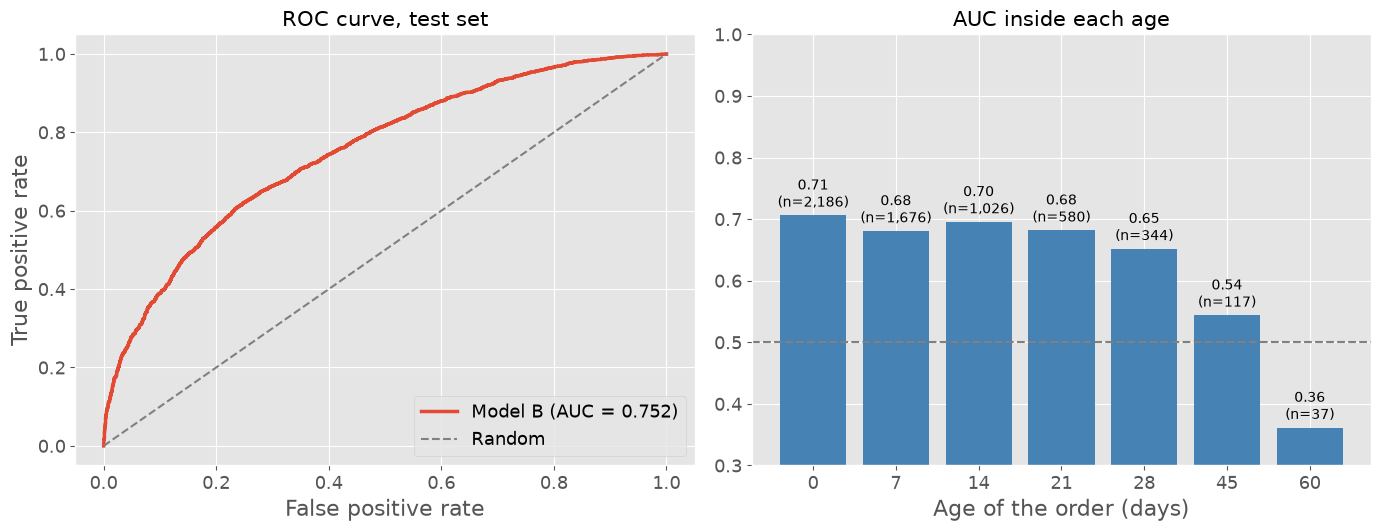

In [7]:
teste_b["prob"] = prever(modelo_b, colunas_b, teste_b, VARS_NUM, VARS_CAT)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

fpr, tpr, _ = roc_curve(teste_b["perda"], teste_b["prob"])
ax1.plot(fpr, tpr, linewidth=2.5, label=f"Model B (AUC = {roc_auc_score(teste_b['perda'], teste_b['prob']):.3f})")
ax1.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random")
ax1.set_xlabel("False positive rate")
ax1.set_ylabel("True positive rate")
ax1.set_title("ROC curve, test set")
ax1.legend(loc="lower right")

dataset_aux = (
    teste_b.groupby("idade_pedido")
    .apply(lambda d: pd.Series({"AUC": roc_auc_score(d["perda"], d["prob"]), "linhas": len(d)}), include_groups=False)
    .reset_index()
)
barras = ax2.bar(dataset_aux["idade_pedido"].astype(str), dataset_aux["AUC"], color="steelblue")
ax2.bar_label(barras, labels=[f"{a:.2f}\n(n={int(n):,})" for a, n in zip(dataset_aux["AUC"], dataset_aux["linhas"])], padding=3, fontsize=10)
ax2.axhline(0.5, color="grey", linestyle="--")
ax2.set_ylim(0.3, 1)
ax2.set_xlabel("Age of the order (days)")
ax2.set_title("AUC inside each age")
plt.tight_layout()
plt.show()

The overall AUC on the test set is 0.75. Inside each age, the AUC stays around 0.65 to 0.71 up to four weeks, which shows that the model is not just using the age: among orders with the same age, it still separates the risky ones from the safe ones.

At 45 and 60 days the AUC loses meaning: there are few rows and almost all of them are losses (97% and 99%, as seen in notebook 03). At that point, the question is no longer "which of these orders will be lost" but "why are these orders still open", and the answer for the sales team is simply to review all of them.

### Calibration
For the sales team, the probability needs to mean something: when the model says 70%, around 70% of those orders should be lost. The graph compares, in deciles of predicted probability, the average prediction with the observed loss rate.

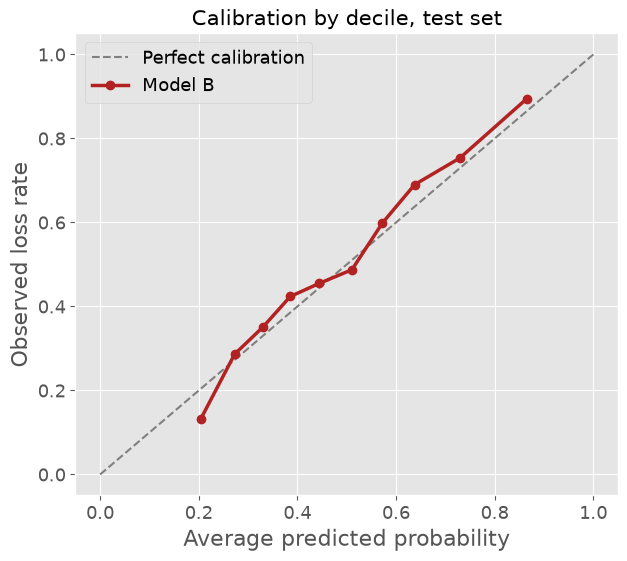

In [8]:
teste_b["decil"] = pd.qcut(teste_b["prob"], 10, labels=False)
dataset_aux = teste_b.groupby("decil").agg(previsto=("prob", "mean"), observado=("perda", "mean"))

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Perfect calibration")
ax.plot(dataset_aux["previsto"], dataset_aux["observado"], marker="o", linewidth=2.5, color="firebrick", label="Model B")
ax.set_xlabel("Average predicted probability")
ax.set_ylabel("Observed loss rate")
ax.set_title("Calibration by decile, test set")
ax.legend()
plt.show()

The points follow the diagonal closely, so the probabilities can be read as probabilities: in the decile where the model predicts 86% on average, 89% of the orders were lost. There is a small overestimation only in the lowest decile (20% predicted against 13% observed), which does not affect the ranking.

### Choosing a cutoff
The model gives a probability, but the sales team needs a decision: "call this customer or not". The table below shows, for some cutoffs, how many orders would be flagged and how good the flag is.

In [9]:
def avaliar_corte(prob, y, cortes):
    linhas = []
    for c in cortes:
        pred = prob >= c
        tp = (pred & (y == 1)).sum(); fp = (pred & (y == 0)).sum()
        fn = (~pred & (y == 1)).sum(); tn = (~pred & (y == 0)).sum()
        linhas.append({
            "cutoff": c,
            "flagged orders": pred.mean(),
            "precision": tp / (tp + fp) if tp + fp > 0 else np.nan,
            "sensitivity": tp / (tp + fn),
            "specificity": tn / (tn + fp),
        })
    return pd.DataFrame(linhas)

avaliar_corte(teste_b["prob"].to_numpy(), teste_b["perda"].to_numpy(), [0.3, 0.4, 0.5, 0.6, 0.7]).style.format(
    {"cutoff": "{:.1f}", "flagged orders": "{:.0%}", "precision": "{:.0%}", "sensitivity": "{:.0%}", "specificity": "{:.0%}"})

,cutoff,flagged orders,precision,sensitivity,specificity
0,0.3,80%,58%,92%,32%
1,0.4,63%,64%,79%,54%
2,0.5,46%,71%,64%,72%
3,0.6,31%,78%,47%,86%
4,0.7,18%,84%,29%,94%


There is no "correct" cutoff, it depends on the capacity of the team. With a cutoff of **0.5**, 46% of the orders are flagged, and 71% of the flagged ones are really lost; 65% of all the losses are caught. With a cutoff of **0.7**, only 18% of the orders are flagged, but the precision goes to 84%, which is ideal for a small team that can only call the most critical cases.

In production, instead of a single cutoff, the orders are ranked and grouped in priority levels (last section of this notebook).

### How far from the best possible model?
This is the advantage of synthetic data: for each order we know the **real probability** that generated its outcome. The AUC of that real probability is the ceiling, the best that any model could reach with these orders, because the rest of the outcome is pure chance.

The comparison is made at age 0 (the moment the order is created), because the real probability does not depend on the age.

In [10]:
teste_0 = teste_b[teste_b["idade_pedido"] == 0].merge(verdade, on="PedidoId")

pd.DataFrame([
    {"Score": "Real probability (ceiling)", "AUC": roc_auc_score(teste_0["perda"], teste_0["prob_real"])},
    {"Score": "Model B at creation", "AUC": roc_auc_score(teste_0["perda"], teste_0["prob"])},
    {"Score": "Correlation model vs real", "AUC": np.corrcoef(teste_0["prob"], teste_0["prob_real"])[0, 1]},
]).round(3)

,Score,AUC
0,Real probability (ceiling),0.758
1,Model B at creation,0.706
2,Correlation model vs real,0.806


At the moment of creation, the real probability reaches an AUC of 0.758; **this is the ceiling**, nothing can do better, because the remaining uncertainty is pure randomness (and the latent customer quality, which no model sees directly). Model B reaches 0.706, capturing about **80% of the discrimination that is possible above a random guess**, and its predictions have a correlation of 0.81 with the real probabilities.

With real data this comparison is impossible, and it is a good way to answer the classic question "is it worth trying to improve the model?". Here, the remaining gap is small and probably comes from the customer quality, which the model can only estimate through the history.

## 5. Explanation with SHAP
A probability alone does not help the sales rep; they need to know **why** the order is at risk. SHAP values decompose each prediction into the contribution of each variable. The graph shows, for a sample of the test set, the variables with the largest impact; each point is an order, red means a high value of the variable and the horizontal position is how much it pushed the risk up or down.

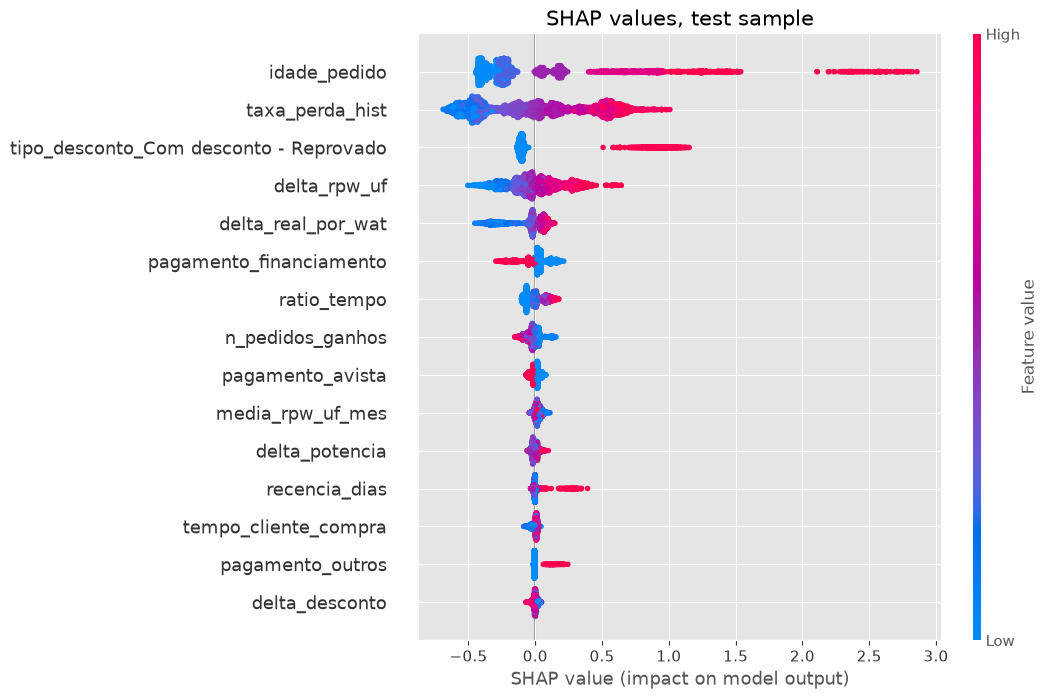

In [11]:
amostra = teste_b.sample(3000, random_state=SEED)
X_amostra = matriz(amostra, VARS_NUM, VARS_CAT, colunas_b)

explicador = shap.TreeExplainer(modelo_b)
valores_shap = explicador.shap_values(X_amostra)
shap.summary_plot(valores_shap, X_amostra, max_display=15, show=False, plot_size=(11, 7))
plt.title("SHAP values, test sample")
plt.show()

The ranking of the variables matches what was seen in the exploratory analysis and what was used to generate the data:

- **Age of the order** is the most important variable: the longer the order stays open, the higher the risk (in a legitimate way now).
- **Historical loss rate of the customer** comes second; it is the model's way to estimate the latent customer quality.
- **Discount rejected** strongly increases the risk.
- **Price per watt above the market of the state** and **above the customer's usual** increase the risk.
- **Cash payment** reduces the risk.

One result looks strange at first: **financing appears reducing the risk** (red points on the left), although financed orders are lost more (46% against 34% in notebook 02). The explanation is an **interaction with the age**:

| Age | Loss rate, financed | Loss rate, not financed |
|-----|---------------------|-------------------------|
| 0 days | 46% | 36% |
| 14 days | 46% | 61% |
| 28 days | 74% | 88% |

At creation, financing is a risk factor. But financed orders that are won take longer to close (19 days on average against 10, because of the bank analysis), so **a financed order that is still open after two weeks is normal**, while a cash order in the same situation is probably abandoned. Since most of the snapshot rows have age above zero, the average SHAP effect of financing is negative. The model learned this interaction by itself, and it is a good example of why a variable should never be interpreted in isolation, the same lesson as the dummy variables of a linear regression.

## Scoring the open orders
Finally, the use of the model. Each open order receives:

- the **probability of loss**;
- a **priority** level, based on fixed quantiles of the training predictions (so that the level does not depend on how many orders are open today);
- an **operational score** = probability × log(1 + value), which puts first the orders that are both risky and valuable;
- the **three main reasons** of its risk, translated from the SHAP values into sentences for the sales team.

In [12]:
abertos["prob"] = prever(modelo_b, colunas_b, abertos, VARS_NUM, VARS_CAT)
abertos["score_operacional"] = abertos["prob"] * np.log1p(abertos["ValorTotal"])

prob_treino = prever(modelo_b, colunas_b, treino_b, VARS_NUM, VARS_CAT)
limites = np.quantile(prob_treino, [0.25, 0.50, 0.75, 0.90])
abertos["prioridade"] = pd.cut(abertos["prob"], [0, *limites, 1], labels=["Very low", "Low", "Medium", "High", "Critical"])

EXPLICACOES = {
    "idade_pedido": "Order open for a long time",
    "ratio_tempo": "Order open longer than usual for this customer",
    "diff_ticket_valor": "Order value far from the customer's usual ticket",
    "mes": "Season of the year",
    "tempo_cliente_compra": "Length of the relationship with the customer",
    "recencia_dias": "Customer has not bought for a long time",
    "n_pedidos_ganhos": "Number of past purchases",
    "taxa_perda_hist": "Customer's historical loss rate",
    "delta_oversize": "Oversize different from the customer's usual",
    "delta_desconto": "Discount different from the customer's usual",
    "delta_potencia": "Kit size different from the customer's usual",
    "delta_real_por_wat": "Price per watt different from the customer's usual",
    "delta_rpw_uf": "Price per watt above the market of the state",
    "media_rpw_uf_mes": "Market price level of the state",
    "pagamento": "Payment method",
    "frete_uf": "Freight type and state",
    "tipo_desconto": "Discount and its approval",
}

def variavel_original(coluna):
    """Maps a one-hot column (e.g. 'pagamento_financiamento') back to its variable."""
    return next((v for v in VARS_CAT if coluna.startswith(v + "_")), coluna)

X_abertos = matriz(abertos, VARS_NUM, VARS_CAT, colunas_b)
contribuicoes = modelo_b.predict(xgb.DMatrix(X_abertos), pred_contribs=True,
                                 iteration_range=(0, modelo_b.best_iteration + 1))[:, :-1]   # the last column is the bias
contribuicoes = pd.DataFrame(contribuicoes, columns=colunas_b).T.groupby(variavel_original).sum().T

top3 = np.argsort(-contribuicoes.to_numpy(), axis=1)[:, :3]   # the three variables that most INCREASE the risk
for i in range(3):
    abertos[f"motivo_{i + 1}"] = [EXPLICACOES[contribuicoes.columns[j]] for j in top3[:, i]]

ranking = abertos.sort_values("score_operacional", ascending=False)
ranking[["NumeroPedido", "CpfCnpj", "idade_pedido", "ValorTotal", "prob", "prioridade", "motivo_1", "motivo_2", "motivo_3"]].head(10).style.format(
    {"ValorTotal": "R$ {:,.0f}", "prob": "{:.0%}"}).hide(axis="index")

NumeroPedido,CpfCnpj,idade_pedido,ValorTotal,prob,prioridade,motivo_1,motivo_2,motivo_3
517572,INT00465,60,"R$ 50,628",96%,Critical,Order open for a long time,Customer's historical loss rate,Order open longer than usual for this customer
517942,INT01049,46,"R$ 34,917",95%,Critical,Order open for a long time,Price per watt above the market of the state,Order open longer than usual for this customer
517307,INT01237,71,"R$ 37,560",94%,Critical,Order open for a long time,Price per watt above the market of the state,Order open longer than usual for this customer
517871,INT01163,49,"R$ 37,057",93%,Critical,Order open for a long time,Customer's historical loss rate,Order open longer than usual for this customer
518340,INT00925,30,"R$ 70,445",88%,Critical,Order open for a long time,Discount and its approval,Customer's historical loss rate
518367,INT01163,29,"R$ 53,348",88%,Critical,Order open for a long time,Customer's historical loss rate,Order open longer than usual for this customer
518678,INT00507,16,"R$ 61,616",86%,Critical,Discount and its approval,Customer's historical loss rate,Payment method
517592,INT00363,59,"R$ 21,321",95%,Critical,Order open for a long time,Discount and its approval,Payment method
518510,INT00101,22,"R$ 53,417",86%,Critical,Discount and its approval,Order open for a long time,Payment method
517536,INT00075,61,"R$ 17,820",95%,Critical,Order open for a long time,Order open longer than usual for this customer,Price per watt above the market of the state


In [13]:
abertos["prioridade"].value_counts().reindex(["Critical", "High", "Medium", "Low", "Very low"]).to_frame("open orders")

,open orders
prioridade,
Critical,51
High,45
Medium,86
Low,84
Very low,118


## Conclusion
The model ranks the open orders by their chance of loss with an AUC of 0.75 in the real conditions of use, well calibrated, and close to the theoretical ceiling of the data. Beyond the numbers, the main lessons of this project are about **validation**:

1. **A feature can look perfect and still be leakage.** The time of the order was the most important variable of the original model, but it was calculated differently in training and in production. The validation reported 0.76 while the real quality was 0.69. Training with **snapshots** fixed it.
2. **The history of the customer must be point-in-time.** Cumulative sums ordered by creation date silently use outcomes that happened after the order.
3. **The order stage is a photo of the outcome.** A model with it reaches AUC 1.0 and is useless.
4. **The test set should never choose the model.** Early stopping uses a separate validation window.
5. **Recent data is censored.** Orders that had no time to close are kept out of the evaluation.

In production, this pipeline runs as two scheduled jobs: a **daily** job that scores the open orders and a **weekly** job that retrains the model and only promotes the new version if its AUC does not drop more than 0.02 from the current one (every training is logged for auditing). The ranking, with the priority and the three reasons of each order, is served by an API to the sales system.

In [14]:
#Cleaning the environment
import gc
del pedidos, snapshots, abertos, verdade, treino_a, valid_a, teste_a, treino_b, valid_b, teste_b, teste_b_como_a, teste_0
gc.collect();